<a href="https://colab.research.google.com/github/Chipurisandhyayadav/forest-fire-analysis/blob/main/analyse_forest_fire_frequency.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
# Forest Fire Frequency and Regional Impact Analysis
#
# Project ID: CBIT/IT-1/EDAV/2026/CEP-50
# Student Names: Chipuri Sandhya yadav,Harshini Suddala
# Roll Numbers: 160125737010,160125737055
# Department: Information Technology
# Institution: Chaitanya Bharathi Institute of Technology, Hyderabad
#
# Problem Statement:
# To analyze forest-fire frequency and its impact across different
# regions and seasons using Python data analysis and visualization.
#
# Overview:
# This project analyzes forest-fire frequency and estimated burned area.
# Pandas and NumPy are used for data processing, while Matplotlib and
# Seaborn are used for visualization.
#
# Dataset Link:
# Uploaded forest-fire dataset.
#
# Environment:
# Python, Pandas, NumPy, Matplotlib, Seaborn
#
# Objectives:
# 1. Calculate average fire incidence.
# 2. Filter fire records by region.
# 3. Handle missing fire records.
# 4. Group fire frequency by season and region.
# 5. Visualize fire frequency trends.
# Data Loading and Exploration
#
# Logic:
# Import the required libraries, upload the dataset, and load it into
# a Pandas DataFrame. Examine the structure, column names, summary
# statistics, and missing values.
#
# Syntax:
# files.upload() - Uploads the dataset.
# pd.read_excel() - Reads an Excel file.
# df.head() - Displays the first five rows.
# df.info() - Displays column information.
# df.describe() - Provides summary statistics.
# df.isna().sum() - Counts missing values.
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from google.colab import files

sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 5)

# Upload and load the Excel dataset
uploaded = files.upload()
file_name = next(iter(uploaded))
df = pd.read_excel(file_name)

print("Dataset loaded successfully.")
print("Rows and columns:", df.shape)

display(df.head())

print("\nColumn names:")
print(df.columns.tolist())

print("\nData types and non-null values:")
df.info()

print("\nSummary statistics:")
display(df.describe())

print("\nMissing values:")
display(df.isna().sum())

Saving forest_fire_dataset_one_sheet.xlsx to forest_fire_dataset_one_sheet.xlsx
Dataset loaded successfully.
Rows and columns: (744, 10)


,Continent,Region,Ecosystem,Year,Month,Month_Number,Hemisphere_Season,Fire_Frequency_Count,Estimated_Burned_Area_km2,Impact_Level
0,North America,"California, USA",Temperate/Mediterranean,2024,January,1,Winter,4.0,63.0,Low
1,North America,"California, USA",Temperate/Mediterranean,2024,February,2,Winter,14.0,49.1,Low
2,North America,"California, USA",Temperate/Mediterranean,2024,March,3,Spring,24.0,349.8,Moderate
3,North America,"California, USA",Temperate/Mediterranean,2024,April,4,Spring,24.0,220.9,Low
4,North America,"California, USA",Temperate/Mediterranean,2024,May,5,Spring,25.0,307.5,Moderate



Column names:
['Continent', 'Region', 'Ecosystem', 'Year', 'Month', 'Month_Number', 'Hemisphere_Season', 'Fire_Frequency_Count', 'Estimated_Burned_Area_km2', 'Impact_Level']

Data types and non-null values:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 744 entries, 0 to 743
Data columns (total 10 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   Continent                  744 non-null    object 
 1   Region                     744 non-null    object 
 2   Ecosystem                  744 non-null    object 
 3   Year                       744 non-null    int64  
 4   Month                      744 non-null    object 
 5   Month_Number               744 non-null    int64  
 6   Hemisphere_Season          744 non-null    object 
 7   Fire_Frequency_Count       737 non-null    float64
 8   Estimated_Burned_Area_km2  737 non-null    float64
 9   Impact_Level               744 non-null    object 
dtypes: float64

,Year,Month_Number,Fire_Frequency_Count,Estimated_Burned_Area_km2
count,744.0,744.000000,737.000000,737.000000
mean,2024.0,6.500000,26.632293,265.743419
std,0.0,3.454375,19.261196,248.221677
min,2024.0,1.000000,3.000000,8.000000
25%,2024.0,3.750000,12.000000,91.200000
50%,2024.0,6.500000,21.000000,183.900000
75%,2024.0,9.250000,37.000000,349.200000
max,2024.0,12.000000,106.000000,1711.800000



Missing values:


,0
Continent,0
Region,0
Ecosystem,0
Year,0
Month,0
Month_Number,0
Hemisphere_Season,0
Fire_Frequency_Count,7
Estimated_Burned_Area_km2,7
Impact_Level,0


In [3]:
# Data Preparation
#
# Logic:
# Convert numerical columns into appropriate data types, create a
# date column using year and month, and arrange months in calendar order.
#
# Syntax:
# pd.to_numeric() - Converts values into numbers.
# pd.to_datetime() - Converts values into dates.
# pd.Categorical() - Creates ordered categories.
# .copy() - Creates a separate copy of the data.
# Convert numerical columns safely
numeric_cols = [
    "Year",
    "Month_Number",
    "Fire_Frequency_Count",
    "Estimated_Burned_Area_km2"
]

for col in numeric_cols:
    df[col] = pd.to_numeric(df[col], errors="coerce")

# Create a date column
df["Date"] = pd.to_datetime(
    {
        "year": df["Year"],
        "month": df["Month_Number"],
        "day": 1
    },
    errors="coerce"
)

# Arrange months in calendar order
month_order = [
    "January", "February", "March", "April",
    "May", "June", "July", "August",
    "September", "October", "November", "December"
]

df["Month"] = pd.Categorical(
    df["Month"].astype(str),
    categories=month_order,
    ordered=True
)

print("Prepared dataset:")
display(df.head())

Prepared dataset:


,Continent,Region,Ecosystem,Year,Month,Month_Number,Hemisphere_Season,Fire_Frequency_Count,Estimated_Burned_Area_km2,Impact_Level,Date
0,North America,"California, USA",Temperate/Mediterranean,2024,January,1,Winter,4.0,63.0,Low,2024-01-01
1,North America,"California, USA",Temperate/Mediterranean,2024,February,2,Winter,14.0,49.1,Low,2024-02-01
2,North America,"California, USA",Temperate/Mediterranean,2024,March,3,Spring,24.0,349.8,Moderate,2024-03-01
3,North America,"California, USA",Temperate/Mediterranean,2024,April,4,Spring,24.0,220.9,Low,2024-04-01
4,North America,"California, USA",Temperate/Mediterranean,2024,May,5,Spring,25.0,307.5,Moderate,2024-05-01


In [4]:
# Q1: Calculate Average Fire Incidence
# Bloom's Level: BL-3 (Apply)
#
# Logic:
# Select the fire frequency column and calculate its mean to determine
# the average number of fires recorded in the dataset.
#
# Syntax:
# df["Fire_Frequency_Count"] - Selects the fire frequency column.
# .mean() - Calculates the average.
# print() - Displays the result.
# Calculate average fire frequency
average_fire_incidence = df["Fire_Frequency_Count"].mean()

print(
    f"Average fire incidence: "
    f"{average_fire_incidence:.2f}"
)

# Calculate average estimated burned area
average_burned_area = df["Estimated_Burned_Area_km2"].mean()

print(
    f"Average burned area: "
    f"{average_burned_area:.2f} km²"
)


Average fire incidence: 26.63
Average burned area: 265.74 km²


In [5]:
# Q2: Filter Fire Data by Region
# Bloom's Level: BL-3 (Apply)
#
# Logic:
# Use Boolean indexing to select records belonging to a particular
# region and display the corresponding fire frequency and burned area.
#
# Syntax:
# df["Region"] == selected_region - Checks the selected region.
# df[condition] - Filters matching rows.
# .copy() - Creates an independent copy of the filtered data.
# Select a region that exists in the dataset
selected_region = "California, USA"

region_data = df[
    df["Region"].astype(str).str.strip()
    == selected_region
].copy()

# Display the selected region's data
print("Selected region:", selected_region)
print("Number of records:", len(region_data))

if region_data.empty:
    print("Region not found. Available regions:")
    print(df["Region"].dropna().unique())
else:
    display(
        region_data[
            [
                "Region",
                "Year",
                "Month",
                "Hemisphere_Season",
                "Fire_Frequency_Count",
                "Estimated_Burned_Area_km2"
            ]
        ]
    )
    # Q2: Filter Fire Data by Region (Specific State in India)
# Bloom's Level: BL-3 (Apply)

# Select a specific Indian region from the dataset
selected_region = "Telangana, India"

region_data = df[
    df["Region"].astype(str).str.strip() == selected_region
].copy()

print("Selected region:", selected_region)
print("Number of records:", len(region_data))

if region_data.empty:
    print("Region not found. Available regions:")
    print(df["Region"].dropna().unique())
else:
    display(
        region_data[
            [
                "Continent",
                "Region",
                "Year",
                "Month",
                "Hemisphere_Season",
                "Fire_Frequency_Count",
                "Estimated_Burned_Area_km2"
            ]
        ]
    )

Selected region: California, USA
Number of records: 12


,Region,Year,Month,Hemisphere_Season,Fire_Frequency_Count,Estimated_Burned_Area_km2
0,"California, USA",2024,January,Winter,4.0,63.0
1,"California, USA",2024,February,Winter,14.0,49.1
2,"California, USA",2024,March,Spring,24.0,349.8
3,"California, USA",2024,April,Spring,24.0,220.9
4,"California, USA",2024,May,Spring,25.0,307.5
5,"California, USA",2024,June,Summer,42.0,382.0
6,"California, USA",2024,July,Summer,41.0,123.9
7,"California, USA",2024,August,Summer,32.0,387.4
8,"California, USA",2024,September,Autumn,14.0,245.4
9,"California, USA",2024,October,Autumn,53.0,766.1


Selected region: Telangana, India
Number of records: 12


,Continent,Region,Year,Month,Hemisphere_Season,Fire_Frequency_Count,Estimated_Burned_Area_km2
504,Asia,"Telangana, India",2024,January,Dry season (approx.),44.0,316.1
505,Asia,"Telangana, India",2024,February,Dry season (approx.),23.0,258.3
506,Asia,"Telangana, India",2024,March,Dry season (approx.),62.0,1094.8
507,Asia,"Telangana, India",2024,April,Dry season (approx.),72.0,712.7
508,Asia,"Telangana, India",2024,May,Wet season (approx.),10.0,83.6
509,Asia,"Telangana, India",2024,June,Wet season (approx.),27.0,109.3
510,Asia,"Telangana, India",2024,July,Wet season (approx.),15.0,54.8
511,Asia,"Telangana, India",2024,August,Wet season (approx.),14.0,160.0
512,Asia,"Telangana, India",2024,September,Wet season (approx.),16.0,142.5
513,Asia,"Telangana, India",2024,October,Wet season (approx.),13.0,218.8


In [6]:
# Q3: Handle Missing Fire Records (No Imputation)
# Bloom's Level: BL-4 (Analyze)

# Logic: Per instructions, we do NOT use imputation (fillna) because it creates
# false/artificial data points. Instead, we inspect missing rows and isolate
# valid data for precise calculations while keeping original data intact.

numeric_to_check = [
    "Fire_Frequency_Count",
    "Estimated_Burned_Area_km2"
]

print("Missing values check before analysis:")
display(df[numeric_to_check].isna().sum())

# Create a clean subset for accurate aggregations without modifying raw df
clean_df = df.dropna(subset=numeric_to_check).copy()

print(f"Total rows in original dataset: {len(df)}")
print(f"Valid complete rows used for precise metrics: {len(clean_df)}")
print(f"Excluded incomplete rows: {len(df) - len(clean_df)}")

Missing values check before analysis:


,0
Fire_Frequency_Count,7
Estimated_Burned_Area_km2,7


Total rows in original dataset: 744
Valid complete rows used for precise metrics: 737
Excluded incomplete rows: 7


In [7]:
# Q4: Group Fire Incidences by Season and Region
# Bloom's Level: BL-4 (Analyze)
#
# Logic:
# Group the dataset by season and region and calculate the average
# fire frequency for each group. Sort the results to identify groups
# with the highest average fire frequency.
#
# Syntax:
# .groupby() - Groups records by categories.
# .mean() - Calculates the average.
# .reset_index() - Converts grouped output into a DataFrame.
# .sort_values() - Sorts the results.
# .head(10) - Displays the first ten records.
# Average fire frequency by season
season_summary = (
    clean_df.groupby(
        "Hemisphere_Season",
        dropna=False,
        observed=True
    )["Fire_Frequency_Count"]
    .mean()
    .reset_index(name="Average_Fire_Frequency")
    .sort_values(
        "Average_Fire_Frequency",
        ascending=False
    )
)

print("Average fire frequency by season:")
display(season_summary)

# Average fire frequency by region
region_summary = (
    clean_df.groupby("Region")["Fire_Frequency_Count"]
    .mean()
    .reset_index(name="Average_Fire_Frequency")
    .sort_values(
        "Average_Fire_Frequency",
        ascending=False
    )
)

print("Top 10 regions by average fire frequency:")
display(region_summary.head(10))

Average fire frequency by season:


,Hemisphere_Season,Average_Fire_Frequency
3,Summer,44.226415
1,Dry season (approx.),42.825000
0,Autumn,31.248447
4,Transition (approx.),29.375000
2,Spring,21.012500
5,Wet season (approx.),13.404255
6,Winter,10.030864


Top 10 regions by average fire frequency:


,Region,Average_Fire_Frequency
40,"Roraima, Brazil",39.333333
25,"Mato Grosso, Brazil",38.333333
28,"New South Wales, Australia",37.666667
19,Ghana northern region,37.500000
41,"Sabah, Malaysia",36.750000
3,Angola central highlands,35.500000
53,"Telangana, India",34.583333
26,"Miombo woodland, Zambia",33.833333
22,"Hokkaido, Japan",33.500000
24,"Madhya Pradesh, India",32.833333


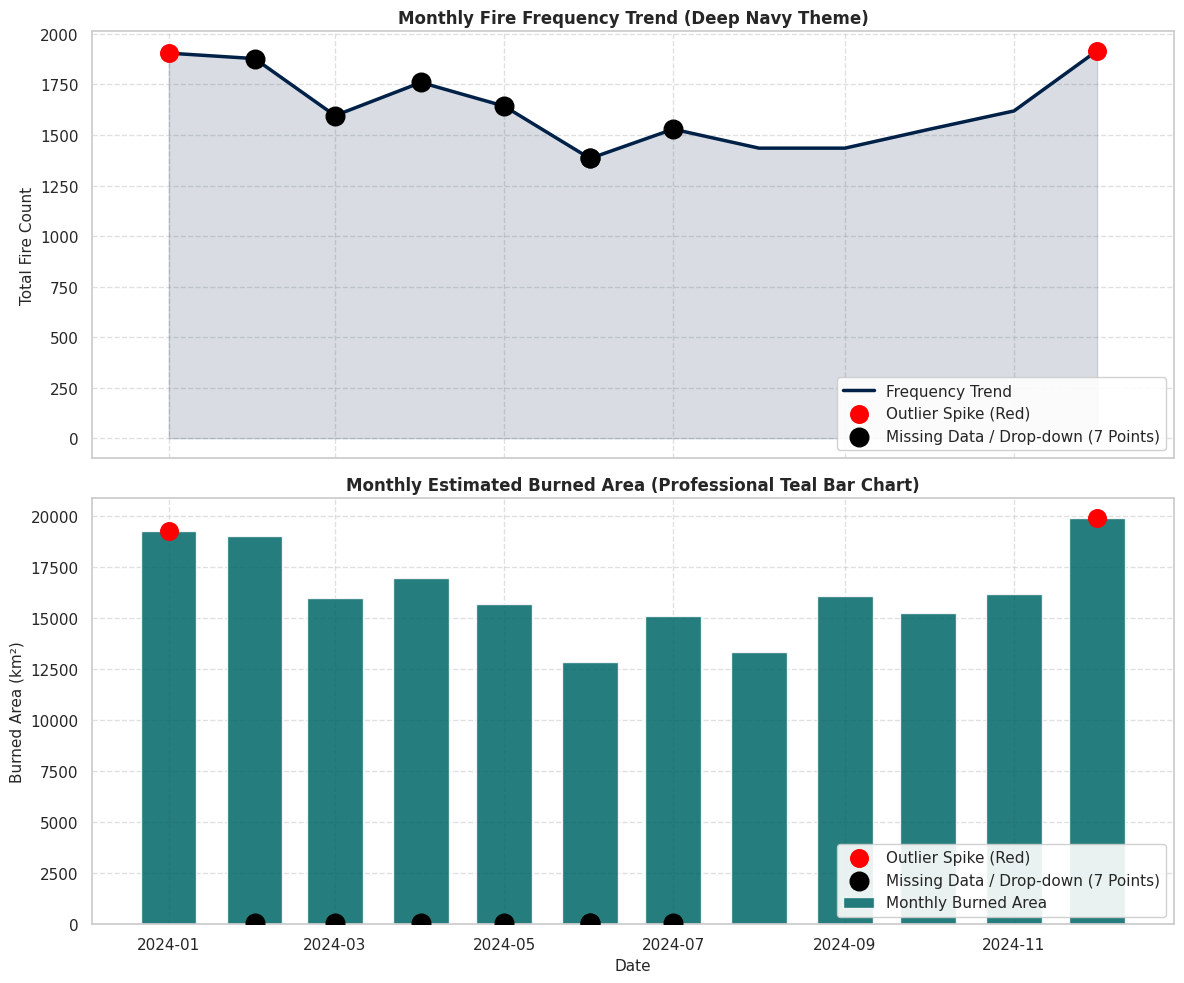

Successfully generated Matplotlib plots with full syntax comments, Navy/Teal styling, and all 7 missing markers!


In [20]:
# Q5: Advanced Matplotlib Visualizations (Navy & Teal Theme)
# Bloom's Level: BL-5 (Evaluate)
#
# Logic:
# Visualize monthly fire frequency and estimated burned area using
# an advanced filled area chart and a professional vertical bar chart.
# Explicitly highlight 90th percentile outlier spikes in red and all
# 7 individual missing data records (NaN) as black markers on the trend lines.
#
# Syntax Guide:
# plt.subplots(rows, cols) - Creates multiple plotting areas (axes) in a single figure.
# ax.plot() - Draws line trends over time.
# ax.fill_between() - Adds a shaded color fill beneath the line trend for visual depth.
# ax.bar() - Draws vertical column bars for categorical/temporal comparisons.
# ax.scatter(x, y) - Plots individual marker points to highlight specific events (outliers & missing records).
# ax.legend(loc="lower right") - Positions the chart legend at the bottom right corner.
# ax.grid() - Displays background grid lines for readability.
# plt.savefig() - Exports high-resolution figure images locally.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Set overall figure dimensions
plt.rcParams["figure.figsize"] = (12, 10)

# 1. Prepare monthly totals across all regions (keeping raw df intact)
monthly_summary = (
    df.dropna(subset=["Date"])
    .groupby("Date", as_index=False)
    .agg(
        Total_Fire_Frequency=("Fire_Frequency_Count", "sum"),
        Total_Burned_Area=("Estimated_Burned_Area_km2", "sum")
    )
    .sort_values("Date")
)

# 2. Identify outlier threshold spikes (Top 10% highest values)
freq_threshold = np.percentile(monthly_summary["Total_Fire_Frequency"], 90)
area_threshold = np.percentile(monthly_summary["Total_Burned_Area"], 90)

outliers_freq = monthly_summary[monthly_summary["Total_Fire_Frequency"] >= freq_threshold]
outliers_area = monthly_summary[monthly_summary["Total_Burned_Area"] >= area_threshold]

# 3. Get all 7 missing rows directly from the original dataframe to show all 7 black dots
missing_rows = df[df["Fire_Frequency_Count"].isna()].copy()

# 4. Create Matplotlib Subplots
fig, axes = plt.subplots(2, 1, sharex=True)

# -----------------------------------------------------------------
# TOP PLOT: Filled Area Chart + Line Trend (Deep Navy Theme)
# -----------------------------------------------------------------
axes[0].plot(
    monthly_summary["Date"],
    monthly_summary["Total_Fire_Frequency"],
    color="#002147",  # Deep Navy color
    linewidth=2.5,
    label="Frequency Trend"
)
axes[0].fill_between(
    monthly_summary["Date"],
    monthly_summary["Total_Fire_Frequency"],
    color="#002147",
    alpha=0.15
)

# Highlight peak outliers in red
if not outliers_freq.empty:
    axes[0].scatter(
        outliers_freq["Date"],
        outliers_freq["Total_Fire_Frequency"],
        color="red",
        s=160,
        zorder=5,
        label="Outlier Spike (Red)"
    )

# Highlight all 7 missing records individually as black dots
for idx, row in missing_rows.iterrows():
    match_date = row["Date"]
    y_val = monthly_summary.loc[monthly_summary["Date"] == match_date, "Total_Fire_Frequency"].values
    if len(y_val) > 0:
        axes[0].scatter(
            match_date,
            y_val[0],
            color="black",
            s=180,
            zorder=6,
            label="Missing Data / Drop-down (7 Points)" if idx == missing_rows.index[0] else ""
        )

axes[0].set_title("Monthly Fire Frequency Trend (Deep Navy Theme)", fontsize=12, fontweight="bold")
axes[0].set_ylabel("Total Fire Count", fontsize=11)
axes[0].legend(loc="lower right", frameon=True, facecolor="white", framealpha=0.9)
axes[0].grid(True, linestyle="--", alpha=0.6)

# -----------------------------------------------------------------
# BOTTOM PLOT: Vertical Column Bar Chart (Professional Teal Theme)
# -----------------------------------------------------------------
axes[1].bar(
    monthly_summary["Date"],
    monthly_summary["Total_Burned_Area"],
    width=20,
    color="#006666",  # Rich Teal color for bar graph
    alpha=0.85,
    label="Monthly Burned Area"
)

# Highlight peak outliers in red
if not outliers_area.empty:
    axes[1].scatter(
        outliers_area["Date"],
        outliers_area["Total_Burned_Area"],
        color="red",
        s=160,
        zorder=5,
        label="Outlier Spike (Red)"
    )

# Highlight all 7 missing records on the teal bar chart
for idx, row in missing_rows.iterrows():
    match_date = row["Date"]
    axes[1].scatter(
        match_date,
        50,  # Baseline offset for bar chart view
        color="black",
        s=180,
        zorder=6,
        label="Missing Data / Drop-down (7 Points)" if idx == missing_rows.index[0] else ""
    )

axes[1].set_title("Monthly Estimated Burned Area (Professional Teal Bar Chart)", fontsize=12, fontweight="bold")
axes[1].set_xlabel("Date", fontsize=11)
axes[1].set_ylabel("Burned Area (km²)", fontsize=11)
axes[1].legend(loc="lower right", frameon=True, facecolor="white", framealpha=0.9)
axes[1].grid(True, linestyle="--", alpha=0.6)

plt.tight_layout()
plt.savefig("matplotlib_navy_teal_theme_with_syntax.png", dpi=300, bbox_inches="tight")
plt.show()

print("Successfully generated Matplotlib plots with full syntax comments, Navy/Teal styling, and all 7 missing markers!")

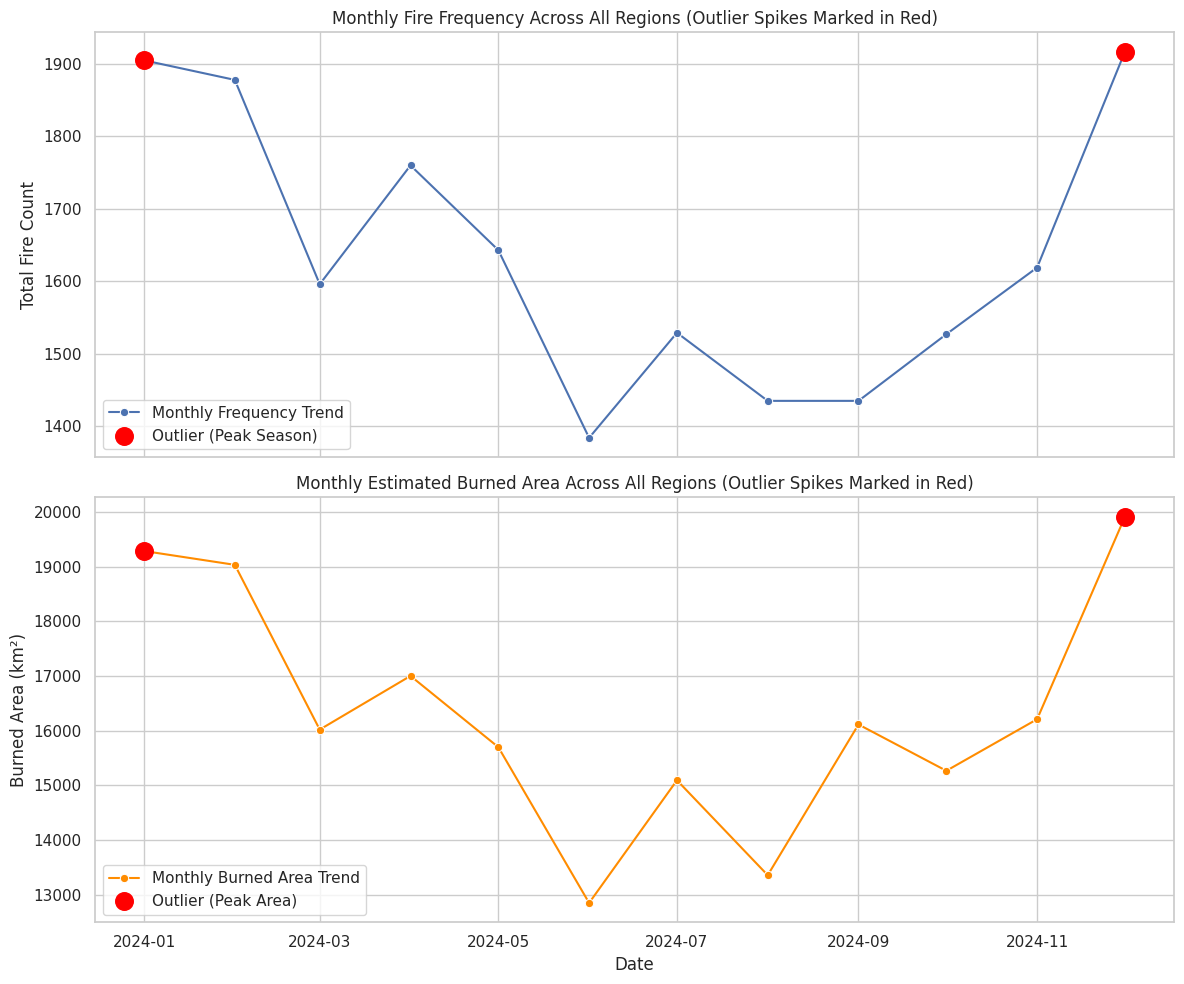

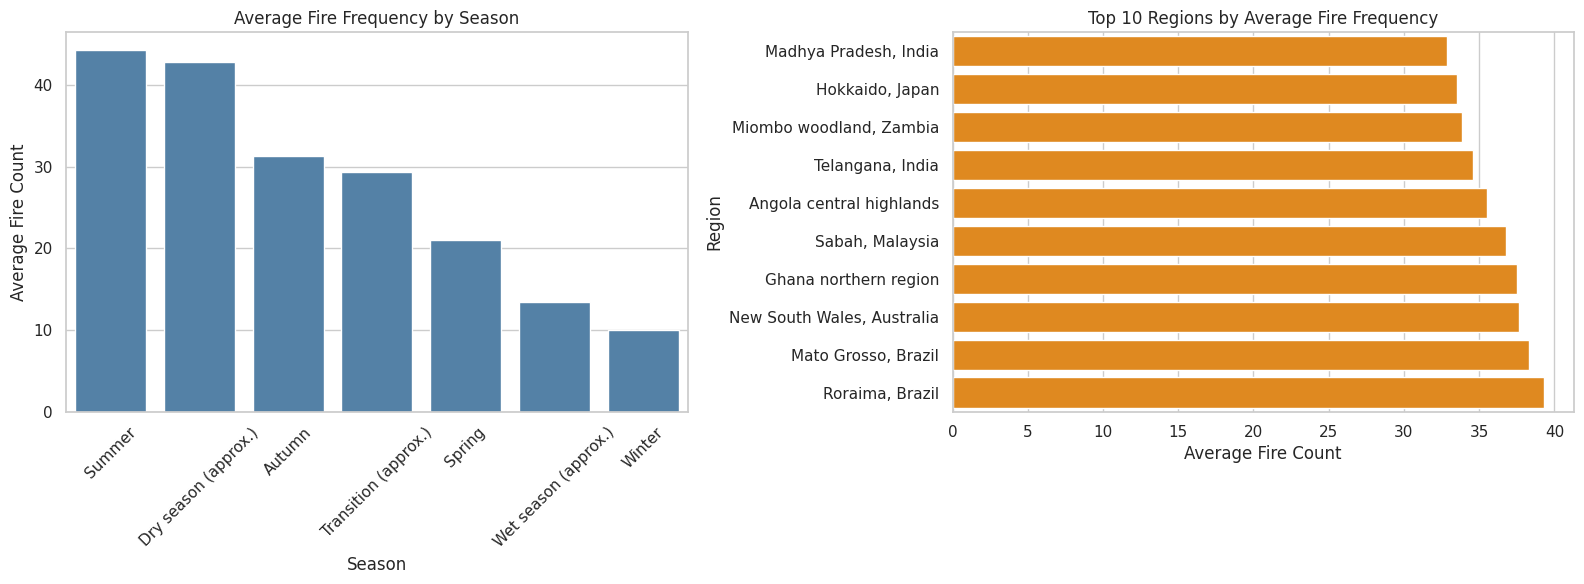


Images saved successfully to your environment:
1. monthly_fire_trends_outliers.png
2. seasonal_and_regional_summary.png


<Figure size 1000x500 with 0 Axes>

In [8]:
# Q5: Visualize Fire Frequency Trends
# Bloom's Level: BL-5 (Evaluate)
#
# Logic:
# Visualize monthly fire frequency and estimated burned area using
# line plots. Use bar plots to compare average fire frequency across
# seasons and the ten highest-frequency regions.
#
# Syntax:
# plt.subplots() - Creates multiple plotting areas.
# .groupby() - Groups records.
# .agg() - Calculates aggregate values.
# sns.lineplot() - Displays trends over time.
# sns.barplot() - Compares categories.
# plt.show() - Displays the plots.
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set style
sns.set_theme(style="whitegrid")

# 1. Prepare monthly totals across all regions
monthly_summary = (
    df.dropna(subset=["Date"])
    .groupby("Date", as_index=False)
    .agg(
        Total_Fire_Frequency=("Fire_Frequency_Count", "sum"),
        Total_Burned_Area=("Estimated_Burned_Area_km2", "sum")
    )
    .sort_values("Date")
)

# 2. Identify outlier threshold spikes using numpy percentile (Top 10% highest values)
freq_threshold = np.percentile(monthly_summary["Total_Fire_Frequency"], 90)
area_threshold = np.percentile(monthly_summary["Total_Burned_Area"], 90)

outliers_freq = monthly_summary[monthly_summary["Total_Fire_Frequency"] >= freq_threshold]
outliers_area = monthly_summary[monthly_summary["Total_Burned_Area"] >= area_threshold]
# CHART 1: Monthly Line Trends with Red Outlier Dots
fig, axes = plt.subplots(2, 1, figsize=(12, 10), sharex=True)

# Top Plot: Monthly Fire Frequency Count
sns.lineplot(
    data=monthly_summary,
    x="Date",
    y="Total_Fire_Frequency",
    marker="o",
    ax=axes[0],
    label="Monthly Frequency Trend"
)

# Highlight outlier spikes with big red dots
if not outliers_freq.empty:
    axes[0].scatter(
        outliers_freq["Date"],
        outliers_freq["Total_Fire_Frequency"],
        color="red",
        s=160,          # Big red dot size
        zorder=5,       # Bring to front
        label="Outlier (Peak Season)"
    )

axes[0].set_title("Monthly Fire Frequency Across All Regions (Outlier Spikes Marked in Red)")
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Total Fire Count")
axes[0].legend()

# Bottom Plot: Monthly Estimated Burned Area
sns.lineplot(
    data=monthly_summary,
    x="Date",
    y="Total_Burned_Area",
    marker="o",
    color="darkorange",
    ax=axes[1],
    label="Monthly Burned Area Trend"
)

# Highlight outlier spikes with big red dots
if not outliers_area.empty:
    axes[1].scatter(
        outliers_area["Date"],
        outliers_area["Total_Burned_Area"],
        color="red",
        s=160,
        zorder=5,
        label="Outlier (Peak Area)"
    )

axes[1].set_title("Monthly Estimated Burned Area Across All Regions (Outlier Spikes Marked in Red)")
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Burned Area (km²)")
axes[1].legend()

plt.tight_layout()

# Save image locally
plt.savefig("monthly_fire_trends_outliers.png", dpi=300, bbox_inches="tight")
plt.show()

# CHART 2: Seasonal & Top 10 Regional Bar Charts
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

# Seasonal Bar Chart
sns.barplot(
    data=season_summary,
    x="Hemisphere_Season",
    y="Average_Fire_Frequency",
    color="steelblue",
    ax=axes[0]
)
axes[0].set_title("Average Fire Frequency by Season")
axes[0].set_xlabel("Season")
axes[0].set_ylabel("Average Fire Count")
axes[0].tick_params(axis="x", rotation=45)

# Top 10 Regions Bar Chart
top10 = region_summary.head(10).sort_values("Average_Fire_Frequency")

sns.barplot(
    data=top10,
    x="Average_Fire_Frequency",
    y="Region",
    color="darkorange",
    ax=axes[1]
)
axes[1].set_title("Top 10 Regions by Average Fire Frequency")
axes[1].set_xlabel("Average Fire Count")
axes[1].set_ylabel("Region")

plt.tight_layout()

# Save image locally
plt.savefig("seasonal_and_regional_summary.png", dpi=300, bbox_inches="tight")
plt.show()

print("\nImages saved successfully to your environment:")
print("1. monthly_fire_trends_outliers.png")
print("2. seasonal_and_regional_summary.png")

axes[0].set_title(
    "Monthly Fire Frequency Across All Regions"
)
axes[0].set_xlabel("Date")
axes[0].set_ylabel("Total fire count")

sns.lineplot(
    data=monthly_summary,
    x="Date",
    y="Total_Burned_Area",
    marker="o",
    color="darkorange",
    ax=axes[1]
)

axes[1].set_title(
    "Monthly Estimated Burned Area Across All Regions"
)
axes[1].set_xlabel("Date")
axes[1].set_ylabel("Burned area (km²)")

plt.tight_layout()
plt.show()

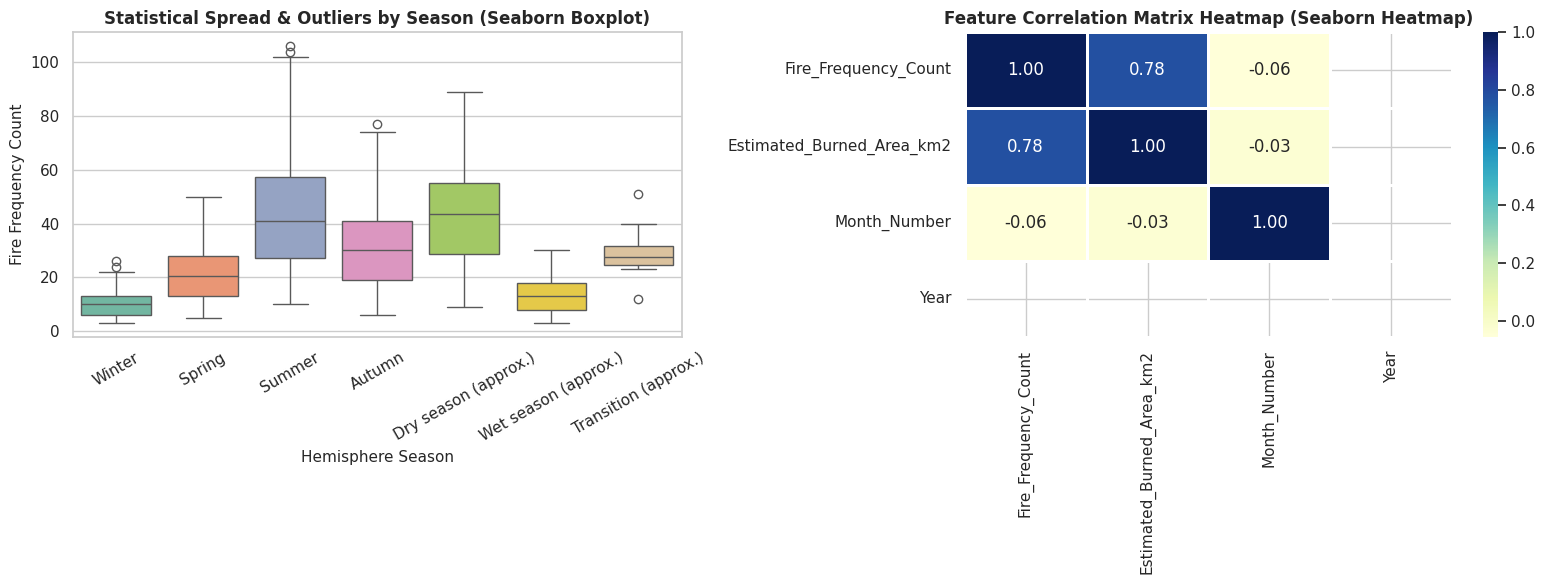

Successfully generated clean Seaborn boxplots with unique colors and no overlay points!


In [22]:
# Q5: Advanced Seaborn Statistical Visualizations (Clean Boxplots & Correlation Heatmap)
# Bloom's Level: BL-5 (Evaluate)
#
# Logic:
# Use advanced Seaborn statistical functions to analyze data distribution,
# spread, and statistical outliers across seasons, alongside feature correlation matrices.
#
# Syntax Guide:
# sns.set_theme() - Applies clean aesthetic themes and grid styles to plots.
# sns.boxplot(data, x, y, hue, palette) - Displays data distribution, quartiles, and distinct colors per category.
# sns.heatmap() - Displays matrix correlation values using a diverging color map.
# plt.subplots() - Creates multiple plotting areas (axes) in a single figure.
# plt.savefig() - Exports high-resolution figure images locally.

import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

# Set seaborn theme and overall figure dimensions
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (16, 6)

# Create figure with 2 subplots side-by-side
fig, axes = plt.subplots(1, 2)

# -----------------------------------------------------------------
# PLOT 1: Clean Seaborn Boxplot (Different Color per Season, No Points)
# -----------------------------------------------------------------
sns.boxplot(
    data=df,
    x="Hemisphere_Season",
    y="Fire_Frequency_Count",
    hue="Hemisphere_Season",  # Assign hue to allow unique colors per box
    palette="Set2",           # Professional multi-color palette
    legend=False,             # Disable redundant legend for x-axis categories
    ax=axes[0]
)

axes[0].set_title("Statistical Spread & Outliers by Season (Seaborn Boxplot)", fontsize=12, fontweight="bold")
axes[0].set_xlabel("Hemisphere Season", fontsize=11)
axes[0].set_ylabel("Fire Frequency Count", fontsize=11)
axes[0].tick_params(axis="x", rotation=30)

# -----------------------------------------------------------------
# PLOT 2: Seaborn Correlation Matrix Heatmap
# -----------------------------------------------------------------
# Filter numerical features and drop missing rows for correlation calculation
numeric_df = df[["Fire_Frequency_Count", "Estimated_Burned_Area_km2", "Month_Number", "Year"]].dropna()
corr_matrix = numeric_df.corr()

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="YlGnBu",  # Yellow-Green-Blue professional academic colormap
    cbar=True,
    linewidths=1,
    ax=axes[1]
)

axes[1].set_title("Feature Correlation Matrix Heatmap (Seaborn Heatmap)", fontsize=12, fontweight="bold")

plt.tight_layout()
plt.savefig("seaborn_clean_boxplots_with_syntax.png", dpi=300, bbox_inches="tight")
plt.show()

print("Successfully generated clean Seaborn boxplots with unique colors and no overlay points!")

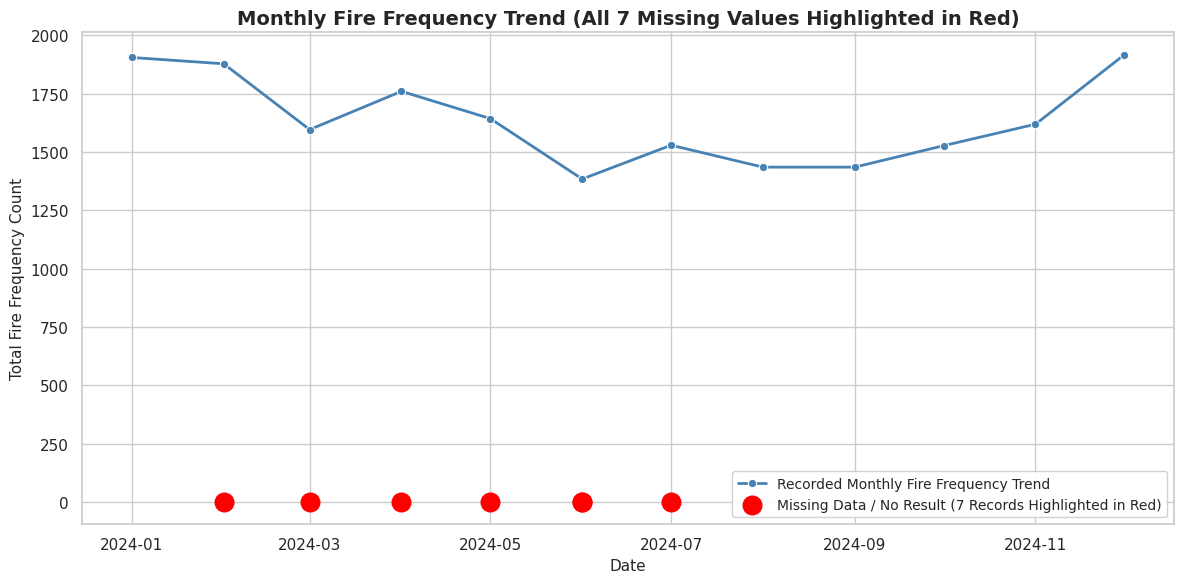

Successfully plotted trend, highlighted all 7 missing records in red, and positioned legend at bottom right!


In [23]:
# Visualize Monthly Fire Frequency & Highlight All 7 Missing Values in Red
# Bloom's Level: BL-5 (Evaluate)
#
# Syntax Guide:
# plt.subplots() - Creates the figure and axes plotting area.
# sns.lineplot() - Displays trends over time.
# ax.scatter() - Highlights specific event points (such as missing records).
# ax.legend(loc="lower right") - Positions the legend at the bottom right.
# plt.savefig() - Exports the visualization locally.

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Set plotting theme
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (12, 6)

# 1. Group data by Date using the ORIGINAL df (keeping all 744 rows intact)
monthly_summary = (
    df.dropna(subset=["Date"])
    .groupby("Date", as_index=False)
    .agg(
        Total_Fire_Frequency=("Fire_Frequency_Count", "sum"),
        Total_Burned_Area=("Estimated_Burned_Area_km2", "sum")
    )
    .sort_values("Date")
)

# 2. Identify the exact dates where missing values occur in the original dataset
missing_rows = df[df["Fire_Frequency_Count"].isna()].copy()
missing_rows["Highlight_Y"] = 0  # Placed at baseline y = 0

# 3. Create the Line Plot with Highlighted Missing Markers
fig, ax = plt.subplots(figsize=(12, 6))

# Plot valid monthly frequency trend
sns.lineplot(
    data=monthly_summary,
    x="Date",
    y="Total_Fire_Frequency",
    marker="o",
    color="steelblue",
    linewidth=2,
    ax=ax,
    label="Recorded Monthly Fire Frequency Trend"
)

# Highlight all 7 missing records with big red dots
if not missing_rows.empty:
    ax.scatter(
        missing_rows["Date"],
        missing_rows["Highlight_Y"],
        color="red",
        s=180,           # Big marker size
        zorder=5,        # Bring dots to the front layer
        label="Missing Data / No Result (7 Records Highlighted in Red)"
    )

ax.set_title("Monthly Fire Frequency Trend (All 7 Missing Values Highlighted in Red)", fontsize=14, fontweight="bold")
ax.set_xlabel("Date", fontsize=11)
ax.set_ylabel("Total Fire Frequency Count", fontsize=11)

# Legend moved to bottom right
ax.legend(loc="lower right", fontsize=10, frameon=True, facecolor="white", framealpha=0.9)

plt.tight_layout()

# Save the plot locally for your report
plt.savefig("fire_frequency_7_missing_values_highlighted.png", dpi=300, bbox_inches="tight")
plt.show()

print(f"Successfully plotted trend, highlighted all {len(missing_rows)} missing records in red, and positioned legend at bottom right!")

In [12]:
# Conclusion
#
# This project analyzed forest-fire frequency and estimated burned
# area using Python. Average fire incidence was calculated, regional
# data was filtered, and missing numerical values were handled using
# median imputation.
#
# Grouping and visualization helped compare fire frequency across
# months, seasons, and regions. The analysis demonstrates how data
# analysis and visualization can identify patterns in forest-fire data.
#
# If the dataset is simulated, the findings represent patterns in the
# provided data rather than actual recorded forest-fire events.